<a href="https://colab.research.google.com/github/sanu08901-rgb/DATA-MINING-PROJECT/blob/main/DataMiningProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== ORIGINAL DATASET ==========
Original records: 541909
Original columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

========== DATA CLEANING ==========
Exact duplicate rows removed: 5268
Valid line-item records: 524878
Unique invoices: 19960
Unique products: 3922

========== BASKET INFORMATION ==========
Number of baskets: 19960
Number of products: 3922
Total product occurrences: 519602

Running Apriori with minimum support = 0.02
Frequent itemsets: 385
Execution time: 5.4520 seconds

Running FP-Growth with minimum support = 0.02
Frequent itemsets: 385
Execution time: 10.9448 seconds

Running Apriori with minimum support = 0.03
Frequent itemsets: 142
Execution time: 2.3577 seconds

Running FP-Growth with minim

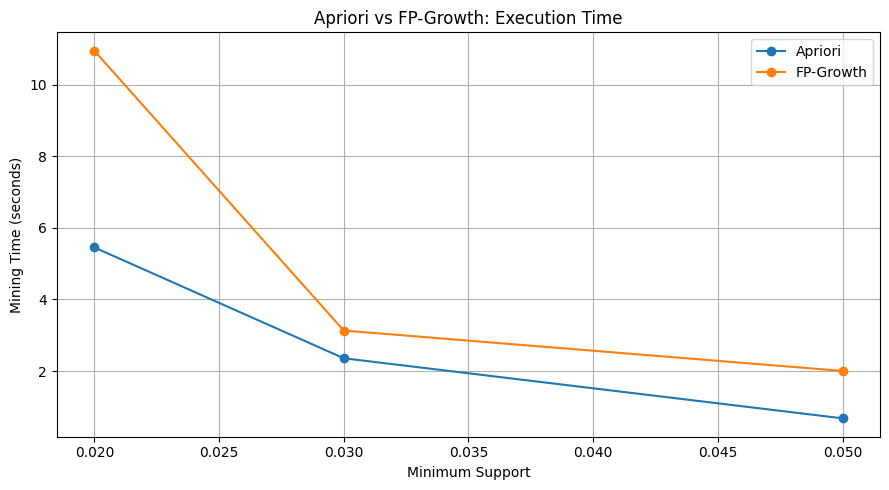

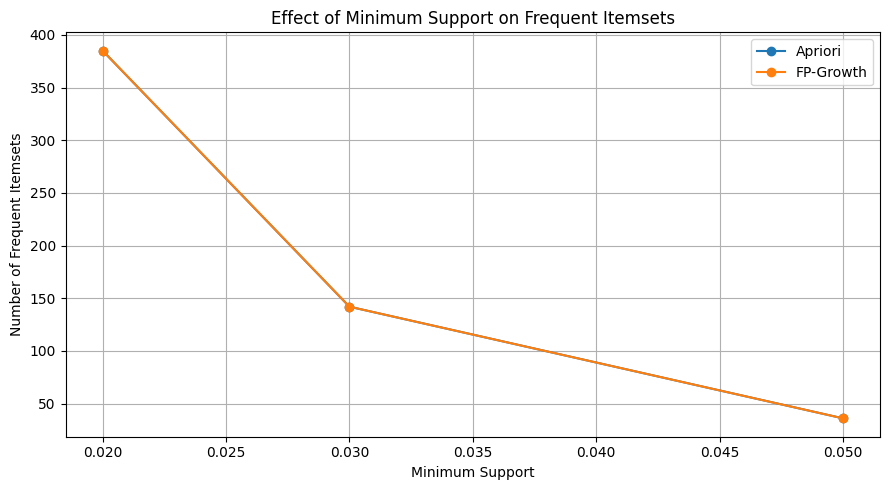

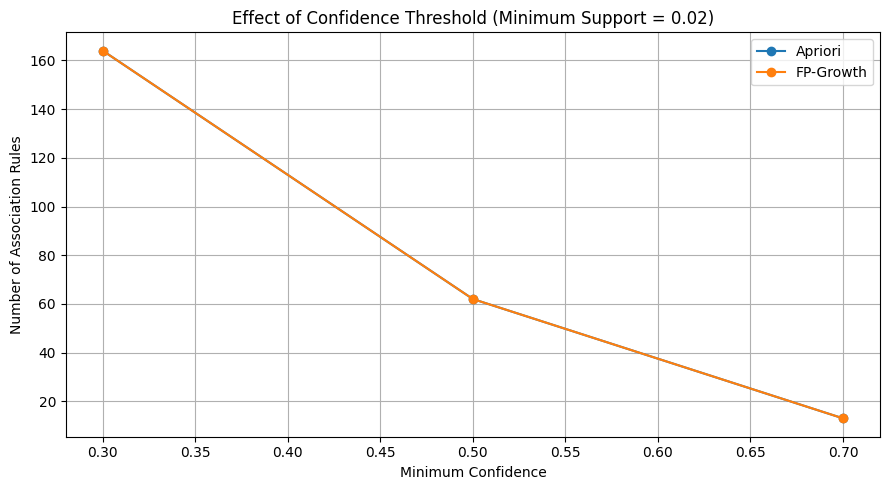


========== PROJECT COMPLETED ==========
All output files are saved in: market_basket_results
Main comparison file: performance_comparison.csv


In [1]:
# ============================================================
# DATA MINING LEVEL 5 INDIVIDUAL PROJECT
# Comparative Performance Analysis of Apriori and FP-Growth
# ============================================================

import os
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, fpgrowth
from mlxtend.frequent_patterns import association_rules

warnings.filterwarnings("ignore")

# -------------------- 1. CONFIGURATION -----------------------

DATA_FILE = "Online Retail.xlsx"
OUTPUT_DIR = "market_basket_results"

# Minimum support values to compare.
# Start with 0.02, 0.03 and 0.05 for a manageable experiment.
SUPPORT_VALUES = [0.02, 0.03, 0.05]

# Confidence thresholds used for generating rules.
CONFIDENCE_VALUES = [0.30, 0.50, 0.70]

# Limit the number of products for faster experiments.
# Set to None to use all products.
MAX_PRODUCTS = None

os.makedirs(OUTPUT_DIR, exist_ok=True)


# -------------------- 2. LOAD DATASET ------------------------

def load_dataset():
    if not os.path.exists(DATA_FILE):
        raise FileNotFoundError(
            f"Dataset not found: {DATA_FILE}\n"
            "Download Online Retail.xlsx and place it "
            "in the same folder as this program."
        )

    df = pd.read_excel(DATA_FILE, engine="openpyxl")

    print("\n========== ORIGINAL DATASET ==========")
    print("Original records:", len(df))
    print("Original columns:", list(df.columns))
    print("\nMissing values:")
    print(df.isnull().sum())

    return df


# -------------------- 3. CLEAN DATA --------------------------

def clean_dataset(df):
    original_rows = len(df)

    # Remove exact duplicate rows.
    df = df.drop_duplicates().copy()
    duplicates_removed = original_rows - len(df)

    # Remove rows without essential transaction information.
    df = df.dropna(
        subset=["InvoiceNo", "StockCode", "Description"]
    ).copy()

    # Convert invoice numbers to strings.
    df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
    df["StockCode"] = df["StockCode"].astype(str).str.strip()
    df["Description"] = df["Description"].astype(str).str.strip()

    # Remove cancelled invoices.
    df = df[~df["InvoiceNo"].str.upper().str.startswith("C")]

    # Keep positive sales quantities and positive prices.
    df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

    # Remove blank product descriptions.
    df = df[df["Description"].str.len() > 0]

    # Report cleaning details.
    print("\n========== DATA CLEANING ==========")
    print("Exact duplicate rows removed:", duplicates_removed)
    print("Valid line-item records:", len(df))
    print("Unique invoices:", df["InvoiceNo"].nunique())
    print("Unique products:", df["StockCode"].nunique())

    # Save cleaned line-item data.
    df.to_csv(
        os.path.join(OUTPUT_DIR, "cleaned_transactions.csv"),
        index=False
    )

    return df


# -------------------- 4. CREATE TRANSACTION BASKETS ----------

def create_baskets(df):
    # One row per invoice and one column per product.
    # Duplicate purchases of the same product in one invoice
    # count as one item for association rule mining.
    basket = (
        df.groupby(["InvoiceNo", "StockCode"])["Quantity"]
        .sum()
        .unstack(fill_value=0)
    )

    # Convert quantities to binary presence/absence.
    basket = (basket > 0).astype(bool)

    # Optional product limit for experimentation.
    if MAX_PRODUCTS is not None:
        frequent_products = (
            basket.sum()
            .sort_values(ascending=False)
            .head(MAX_PRODUCTS)
            .index
        )
        basket = basket[frequent_products]

    # Remove baskets with no products.
    basket = basket.loc[basket.any(axis=1)]

    print("\n========== BASKET INFORMATION ==========")
    print("Number of baskets:", len(basket))
    print("Number of products:", basket.shape[1])
    print("Total product occurrences:", int(basket.sum().sum()))

    # Save basket matrix.
    basket.astype(int).to_csv(
        os.path.join(OUTPUT_DIR, "basket_matrix.csv")
    )

    return basket


# -------------------- 5. RUN ALGORITHMS ----------------------

def run_algorithm(basket, algorithm, min_support):
    start = time.perf_counter()

    if algorithm == "Apriori":
        itemsets = apriori(
            basket,
            min_support=min_support,
            use_colnames=True,
            low_memory=True
        )

    elif algorithm == "FP-Growth":
        itemsets = fpgrowth(
            basket,
            min_support=min_support,
            use_colnames=True
        )

    else:
        raise ValueError("Unknown algorithm")

    elapsed = time.perf_counter() - start

    return itemsets, elapsed


# -------------------- 6. GENERATE ASSOCIATION RULES ----------

def generate_rules(itemsets, min_confidence):
    if itemsets.empty:
        return pd.DataFrame(
            columns=[
                "antecedents", "consequents",
                "antecedent support", "consequent support",
                "support", "confidence", "lift"
            ]
        )

    # Calculate all rules meeting the confidence threshold.
    rules = association_rules(
        itemsets,
        metric="confidence",
        min_threshold=min_confidence
    )

    return rules


def readable_itemsets(series):
    return series.apply(
        lambda items: ", ".join(sorted(map(str, items)))
    )


def prepare_rules_for_export(rules):
    rules = rules.copy()

    if rules.empty:
        return rules

    rules["antecedents"] = readable_itemsets(rules["antecedents"])
    rules["consequents"] = readable_itemsets(rules["consequents"])

    columns = [
        "antecedents", "consequents",
        "support", "confidence", "lift"
    ]

    return rules[columns].sort_values(
        by=["lift", "confidence", "support"],
        ascending=False
    )


# -------------------- 7. EXPERIMENTAL COMPARISON --------------

def run_experiments(basket):
    summary = []
    all_itemsets = {}
    all_rules = {}

    for support in SUPPORT_VALUES:
        for algorithm in ["Apriori", "FP-Growth"]:

            print(
                f"\nRunning {algorithm} "
                f"with minimum support = {support:.2f}"
            )

            itemsets, execution_time = run_algorithm(
                basket, algorithm, support
            )

            all_itemsets[(algorithm, support)] = itemsets

            print("Frequent itemsets:", len(itemsets))
            print(f"Execution time: {execution_time:.4f} seconds")

            # Export frequent itemsets.
            if not itemsets.empty:
                itemset_export = itemsets.copy()
                itemset_export["itemsets"] = readable_itemsets(
                    itemset_export["itemsets"]
                )

                filename = (
                    f"{algorithm.lower().replace('-', '_')}_"
                    f"itemsets_support_{support:.2f}.csv"
                )

                itemset_export.to_csv(
                    os.path.join(OUTPUT_DIR, filename),
                    index=False
                )

            # Generate rules at different confidence thresholds.
            for confidence in CONFIDENCE_VALUES:
                rule_start = time.perf_counter()

                rules = generate_rules(itemsets, confidence)

                rule_time = time.perf_counter() - rule_start

                all_rules[(algorithm, support, confidence)] = rules

                exported_rules = prepare_rules_for_export(rules)

                filename = (
                    f"{algorithm.lower().replace('-', '_')}_"
                    f"rules_support_{support:.2f}_"
                    f"confidence_{confidence:.2f}.csv"
                )

                exported_rules.to_csv(
                    os.path.join(OUTPUT_DIR, filename),
                    index=False
                )

                summary.append({
                    "Algorithm": algorithm,
                    "Minimum Support": support,
                    "Minimum Confidence": confidence,
                    "Frequent Itemsets": len(itemsets),
                    "Association Rules": len(rules),
                    "Mining Time (seconds)": execution_time,
                    "Rule Generation Time (seconds)": rule_time
                })

    summary_df = pd.DataFrame(summary)

    summary_df.to_csv(
        os.path.join(OUTPUT_DIR, "performance_comparison.csv"),
        index=False
    )

    print("\n========== PERFORMANCE COMPARISON ==========")
    print(summary_df.to_string(index=False))

    return summary_df, all_itemsets, all_rules


# -------------------- 8. DISPLAY TOP RULES -------------------

def display_top_rules(all_rules):
    print("\n========== TOP ASSOCIATION RULES ==========")

    # Use the first support and confidence settings for
    # a consistent demonstration.
    support = SUPPORT_VALUES[0]
    confidence = CONFIDENCE_VALUES[0]

    for algorithm in ["Apriori", "FP-Growth"]:
        rules = all_rules[(algorithm, support, confidence)]

        print(
            f"\n{algorithm}: support >= {support}, "
            f"confidence >= {confidence}"
        )

        if rules.empty:
            print("No rules found at these thresholds.")
            continue

        display = prepare_rules_for_export(rules)
        print(display.head(10).to_string(index=False))


# -------------------- 9. PERFORMANCE CHARTS ------------------

def create_charts(summary_df):
    # Remove repeated confidence rows because itemset mining
    # time and itemset count do not depend on confidence.
    mining_summary = (
        summary_df[
            [
                "Algorithm", "Minimum Support",
                "Frequent Itemsets", "Mining Time (seconds)"
            ]
        ]
        .drop_duplicates()
    )

    # Chart 1: execution time.
    plt.figure(figsize=(9, 5))

    for algorithm in ["Apriori", "FP-Growth"]:
        subset = mining_summary[
            mining_summary["Algorithm"] == algorithm
        ]

        plt.plot(
            subset["Minimum Support"],
            subset["Mining Time (seconds)"],
            marker="o",
            label=algorithm
        )

    plt.xlabel("Minimum Support")
    plt.ylabel("Mining Time (seconds)")
    plt.title("Apriori vs FP-Growth: Execution Time")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, "execution_time.png")
    )
    plt.show()

    # Chart 2: number of frequent itemsets.
    plt.figure(figsize=(9, 5))

    for algorithm in ["Apriori", "FP-Growth"]:
        subset = mining_summary[
            mining_summary["Algorithm"] == algorithm
        ]

        plt.plot(
            subset["Minimum Support"],
            subset["Frequent Itemsets"],
            marker="o",
            label=algorithm
        )

    plt.xlabel("Minimum Support")
    plt.ylabel("Number of Frequent Itemsets")
    plt.title("Effect of Minimum Support on Frequent Itemsets")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, "frequent_itemsets.png")
    )
    plt.show()

    # Chart 3: number of association rules.
    rule_summary = (
        summary_df.groupby(
            ["Algorithm", "Minimum Support", "Minimum Confidence"]
        )["Association Rules"]
        .sum()
        .reset_index()
    )

    support = SUPPORT_VALUES[0]

    plt.figure(figsize=(9, 5))

    for algorithm in ["Apriori", "FP-Growth"]:
        subset = rule_summary[
            (rule_summary["Algorithm"] == algorithm)
            & (rule_summary["Minimum Support"] == support)
        ]

        plt.plot(
            subset["Minimum Confidence"],
            subset["Association Rules"],
            marker="o",
            label=algorithm
        )

    plt.xlabel("Minimum Confidence")
    plt.ylabel("Number of Association Rules")
    plt.title(
        f"Effect of Confidence Threshold "
        f"(Minimum Support = {support})"
    )
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, "association_rules.png")
    )
    plt.show()


# -------------------- 10. MAIN PROGRAM -----------------------

def main():
    raw_data = load_dataset()

    cleaned_data = clean_dataset(raw_data)

    basket = create_baskets(cleaned_data)

    summary_df, itemsets, rules = run_experiments(basket)

    display_top_rules(rules)

    create_charts(summary_df)

    print("\n========== PROJECT COMPLETED ==========")
    print("All output files are saved in:", OUTPUT_DIR)
    print("Main comparison file: performance_comparison.csv")


if __name__ == "__main__":
    main()